In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os

%matplotlib inline
os.makedirs("charts", exist_ok=True)
print("Ready")

Ready


In [2]:
import os
print(os.getcwd())

C:\Users\vishu\Downloads\Superstore_analysis\Notebook codes


### Chart 1, Profit by Region (bar chart)

In [3]:
os.makedirs("../charts", exist_ok=True)

In [4]:
df = pd.read_csv("../superstore_clean.csv", dtype={"postal_code": str})

In [5]:
#region = pd.read_csv("superstore_clean.csv").sort_values("total_profit", ascending=False)

region = (df.groupby("region")[["sales", "profit"]].sum().round(2)
            .reset_index()
            .rename(columns={"sales": "total_sales", "profit": "total_profit"})
            .sort_values("total_profit", ascending=False))
region


,region,total_sales,total_profit
3,West,725457.82,108418.45
1,East,678499.87,91534.84
2,South,391721.90,46749.43
0,Central,501239.89,39706.36


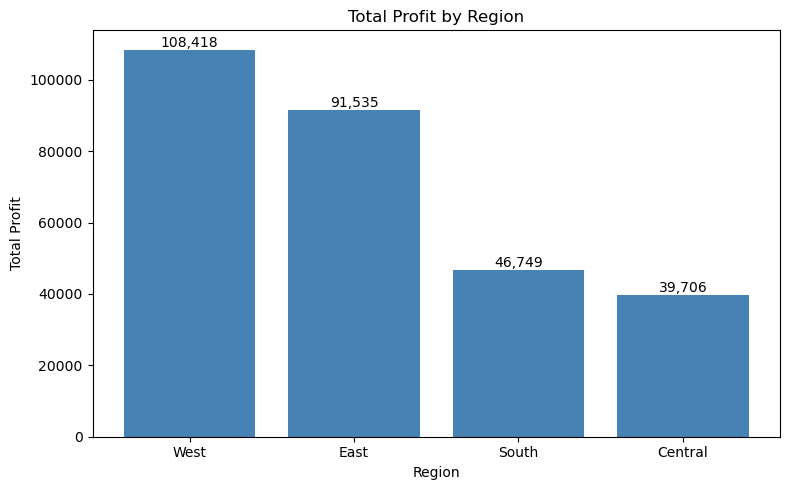

In [6]:
plt.figure(figsize=(8, 5))
plt.bar(region["region"], region["total_profit"], color="steelblue")
plt.title("Total Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")

for i, v in enumerate(region["total_profit"]):
    plt.text(i, v, f"{v:,.0f}", ha="center", va="bottom")

plt.tight_layout()
plt.savefig("../charts/1_profit_by_region.png", dpi=150)
plt.show()

### Chart 2: Profit by Sub-Category (horizontal bar)

In [7]:
sub = (df.groupby(["category", "sub_category"])["profit"].sum().round(2)
         .reset_index()
         .rename(columns={"profit": "total_profit"})
         .sort_values("total_profit"))
sub

,category,sub_category,total_profit
3,Furniture,Tables,-17725.48
0,Furniture,Bookcases,-3472.56
12,Office Supplies,Supplies,-1189.10
8,Office Supplies,Fasteners,949.52
15,Technology,Machines,3384.76
9,Office Supplies,Labels,5546.25
5,Office Supplies,Art,6527.79
7,Office Supplies,Envelopes,6964.18
2,Furniture,Furnishings,13059.14
4,Office Supplies,Appliances,18138.01


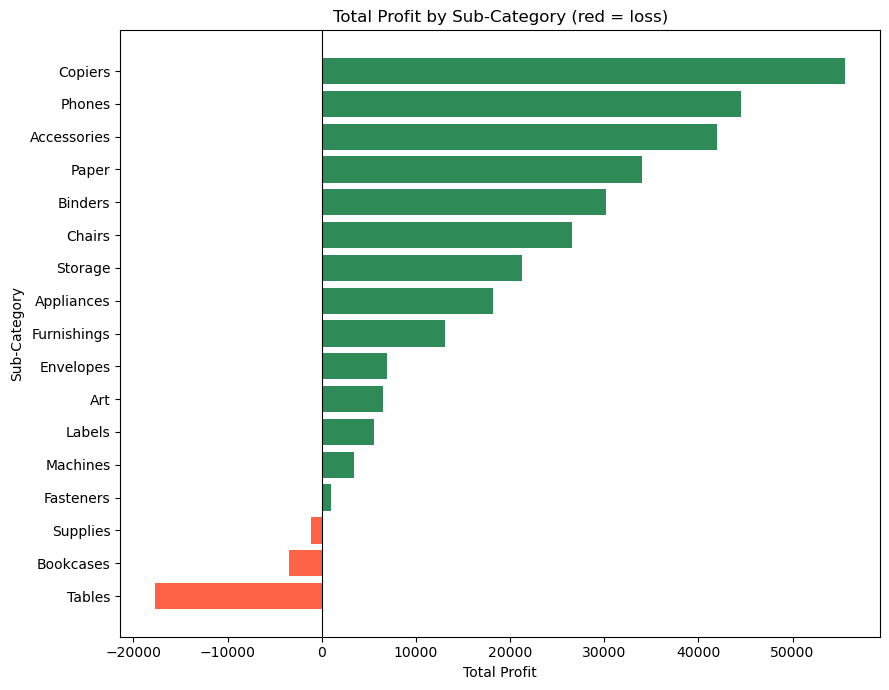

In [8]:
colors = ["tomato" if v < 0 else "seagreen" for v in sub["total_profit"]]

plt.figure(figsize=(9, 7))
plt.barh(sub["sub_category"], sub["total_profit"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Total Profit by Sub-Category (red = loss)")
plt.xlabel("Total Profit")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.savefig("../charts/2_profit_by_subcategory.png", dpi=150)
plt.show()

### Chart 3: Discount vs Average Profit (line chart)

In [9]:
disc = (df.groupby("discount")["profit"].mean().round(2)
          .reset_index()
          .rename(columns={"profit": "avg_profit"})
          .sort_values("discount"))
disc

,discount,avg_profit
0,0.00,66.90
1,0.10,96.06
2,0.15,27.29
3,0.20,24.70
4,0.30,-45.83
5,0.32,-88.56
6,0.40,-111.93
7,0.45,-226.65
8,0.50,-310.70
9,0.60,-43.08


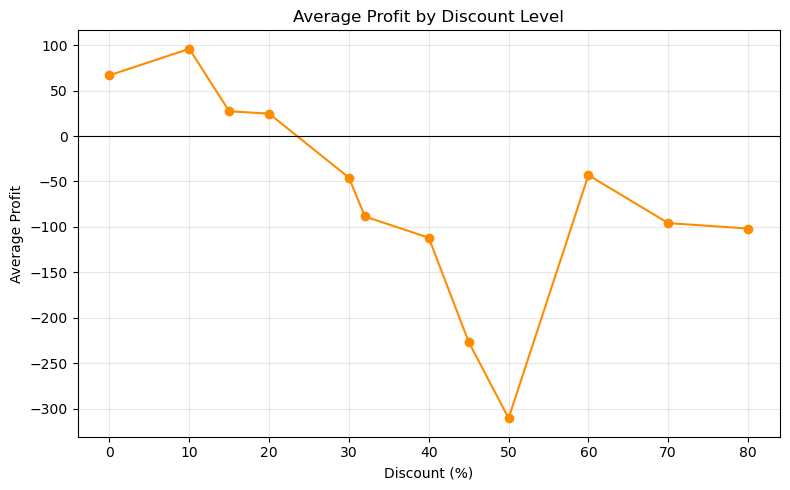

In [10]:
plt.figure(figsize=(8, 5))
plt.plot(disc["discount"] * 100, disc["avg_profit"], marker="o", color="darkorange")
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Average Profit by Discount Level")
plt.xlabel("Discount (%)")
plt.ylabel("Average Profit")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../charts/3_discount_vs_profit.png", dpi=150)
plt.show()

In [11]:
df["discount"].value_counts().sort_index()

0.00    4798
0.10      94
0.15      52
0.20    3657
0.30     226
0.32      27
0.40     206
0.45      11
0.50      66
0.60     138
0.70     418
0.80     300
Name: discount, dtype: int64

### Chart 4: Monthly Sales and Profit (line chart)

In [12]:
monthly = (df.groupby(["order_year", "order_month"])[["sales", "profit"]].sum().round(2)
             .reset_index()
             .rename(columns={"sales": "total_sales", "profit": "total_profit"})
             .sort_values(["order_year", "order_month"]))

monthly["date"] = pd.to_datetime(
    dict(year=monthly["order_year"], month=monthly["order_month"], day=1)
)
monthly.head()

,order_year,order_month,total_sales,total_profit,date
0,2014,1,14236.90,2450.19,2014-01-01
1,2014,2,4519.89,862.31,2014-02-01
2,2014,3,55691.01,498.73,2014-03-01
3,2014,4,28013.97,3500.89,2014-04-01
4,2014,5,23648.29,2738.71,2014-05-01


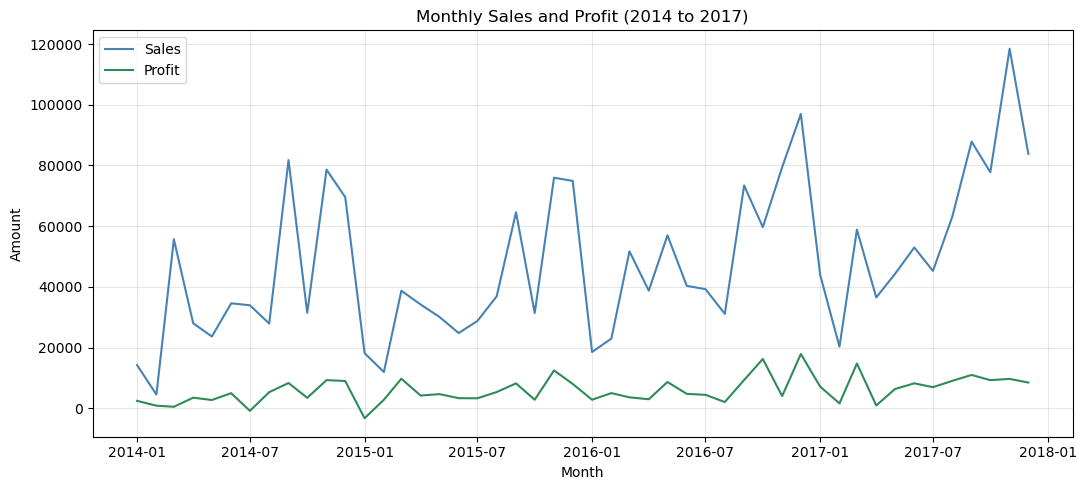

In [13]:
plt.figure(figsize=(11, 5))
plt.plot(monthly["date"], monthly["total_sales"], label="Sales", color="steelblue")
plt.plot(monthly["date"], monthly["total_profit"], label="Profit", color="seagreen")
plt.title("Monthly Sales and Profit (2014 to 2017)")
plt.xlabel("Month")
plt.ylabel("Amount")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../charts/4_monthly_trend.png", dpi=150)
plt.show()

In [14]:
# the exact peak months
monthly.sort_values("total_sales", ascending=False).head(5)

,order_year,order_month,total_sales,total_profit,date
46,2017,11,118447.82,9690.10,2017-11-01
35,2016,12,96999.04,17885.31,2016-12-01
44,2017,9,87866.65,10991.56,2017-09-01
47,2017,12,83829.32,8483.35,2017-12-01
8,2014,9,81777.35,8328.10,2014-09-01
